# K-means para imágenes de galaxias

En este notebook aplicaremos método de k-means a galaxias del desafío Kaggle Galaxy Zoo

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)


In [1]:
import numpy as np
import pandas as pd
import os
import random
import matplotlib.pyplot as plt

import skimage
from skimage.transform import resize, rescale
from skimage import io
from skimage.feature import blob_dog, blob_log, blob_doh
from skimage.color import rgb2gray

Este conjunto de datos está compuesto por 200 imágenes seleccionadas al azar del desafío Kaggle Galaxy Zoo:

https://www.kaggle.com/c/galaxy-zoo-the-galaxy-challenge

El siguiente código visualiza los primeros 25 objetos en nuestro conjunto de datos. Podemos ejecutarlo para obtener una vista de las primeras 25 galaxias. Nota: es posible que reciba un mensaje de error, en este caso, consulte aquí

https://stackoverflow.com/questions/43288550/iopub-data-rate-exceeded-in-jupyter-notebook-when-viewing-image

Las imágenes que usaremos fueron procesadas para eliminar otras fuentes distintas a la central

In [2]:
ruta = 'NoSources_Images/NoSources_Image_'

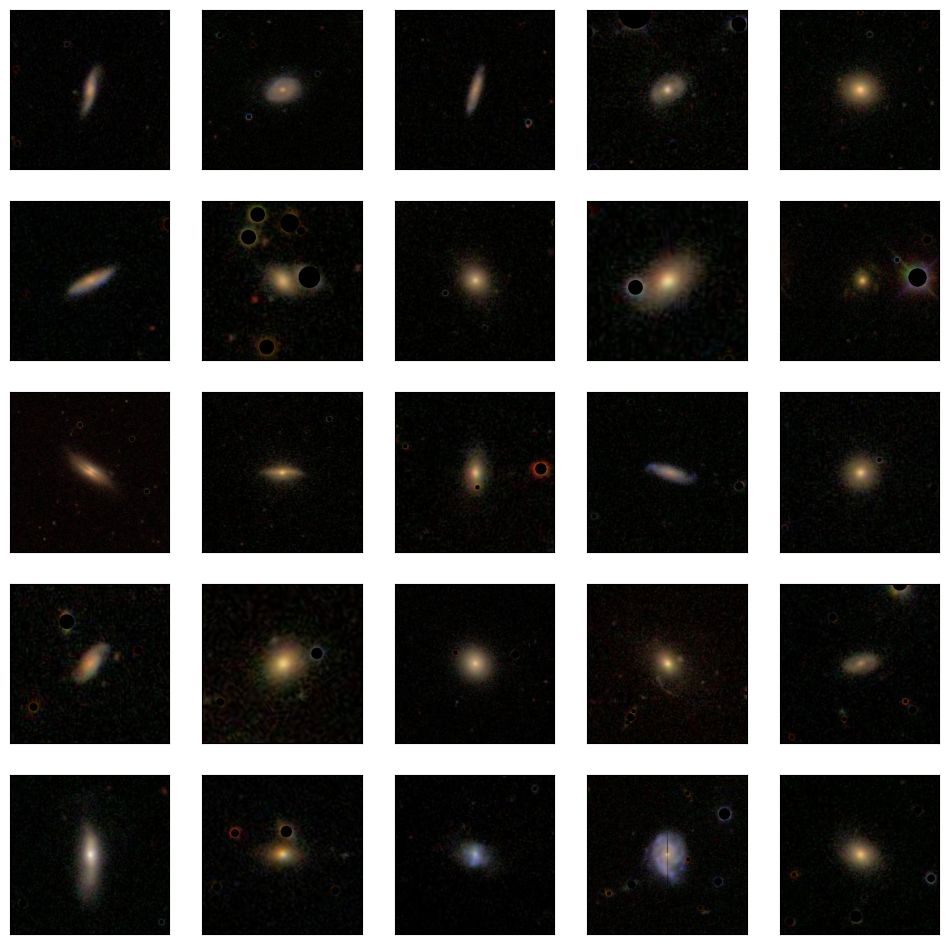

In [3]:
fig, axes = plt.subplots(ncols= 5, nrows = 5,figsize=(12,12))

ax = axes.ravel()

for i in range(ax.shape[0]):

    img = skimage.io.imread(ruta+str(i)+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

In [4]:
images = []

for i in range(200):
    img =skimage.io.imread(ruta+str(i)+'.png')
    img_resized = resize(img,(100,100))
    length = np.prod(img_resized.shape)
    img_resized = np.reshape(img_resized,length)
    images.append(img_resized)

images = np.vstack(images)

In [5]:
images.shape

(200, 30000)

In [6]:
images

array([[0.00072045, 0.00072045, 0.00072045, ..., 0.04023101, 0.03631007,
        0.02847539],
       [0.00256149, 0.00923536, 0.00092913, ..., 0.01534901, 0.01534901,
        0.00853146],
       [0.01312521, 0.01312521, 0.01312521, ..., 0.02014842, 0.02014717,
        0.01261165],
       ...,
       [0.00229134, 0.01401319, 0.00168676, ..., 0.0106061 , 0.0106061 ,
        0.0106061 ],
       [0.03084319, 0.03084319, 0.02301529, ..., 0.02839959, 0.03232301,
        0.01433026],
       [0.01358463, 0.01358463, 0.01358463, ..., 0.01650169, 0.0241105 ,
        0.02018779]])

### Los datos no están etiquetados, por lo que usaremos K-Means para poder agruparlos.

Cuántos grupos cree que podemos encontrar en los datos? implemente K-means para esa cantidad

- `nclusters`: número de grupos
- `n_init`: controla cuántas veces K-means se ejecutará desde distintos puntos de inicio (semillas aleatorias).
Luego, se elige el resultado que tenga el menor error (es decir, el mejor agrupamiento).

### Antes de fijar el número de grupos, probemos con el método del codo y silhouette score

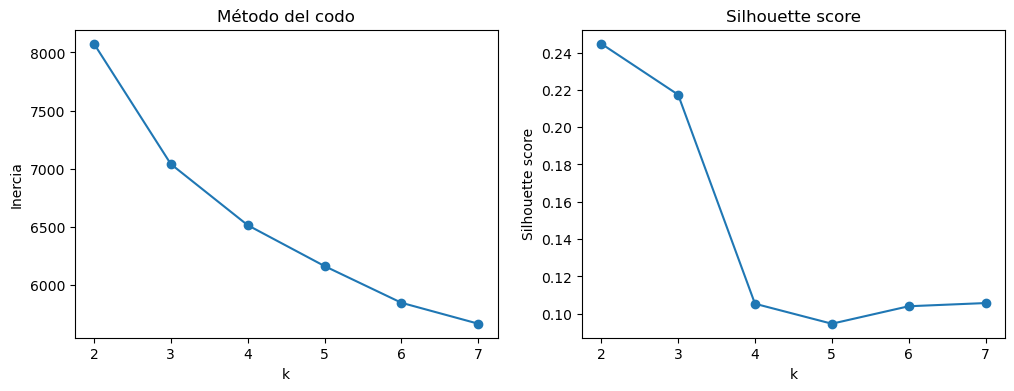

In [7]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

inercias = []
silhouettes = []
rango_k = range(2, 8)

for k in rango_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=10)
    etiquetas = km.fit_predict(images)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(images, etiquetas))

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(rango_k, inercias, 'o-')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inercia')
axes[0].set_title('Método del codo')

axes[1].plot(rango_k, silhouettes, 'o-')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score')

plt.show()

Según estos gráficos, ¿qué valor de k elegirían?

k = 3. El silhouette es mayor en k = 2 y 3 y cae fuerte desde k = 4, y el codo de la inercia está cerca de k = 3.

In [8]:
grupos = 3

kmeans = KMeans(n_clusters=grupos, n_init=10, random_state=10)
kmeans.fit(images)
y_kmeans = kmeans.predict(images)

In [9]:
y_kmeans

array([1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 2, 0,
       1, 1, 1, 1, 2, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1,
       0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 1, 1, 1, 0, 2, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 2,
       1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0,
       1, 1], dtype=int32)

In [10]:
print(len(np.where([y_kmeans == 0])[1]))

57


In [11]:
for g in range(grupos):
    print(g, len(np.where([y_kmeans == g])[1]))

0 57
1 139
2 4


#### Podemos usar el código a continuación para observar 25 galaxias que fueron colocadas en cada  cluster y ver si tienen algún tipo de similitud.

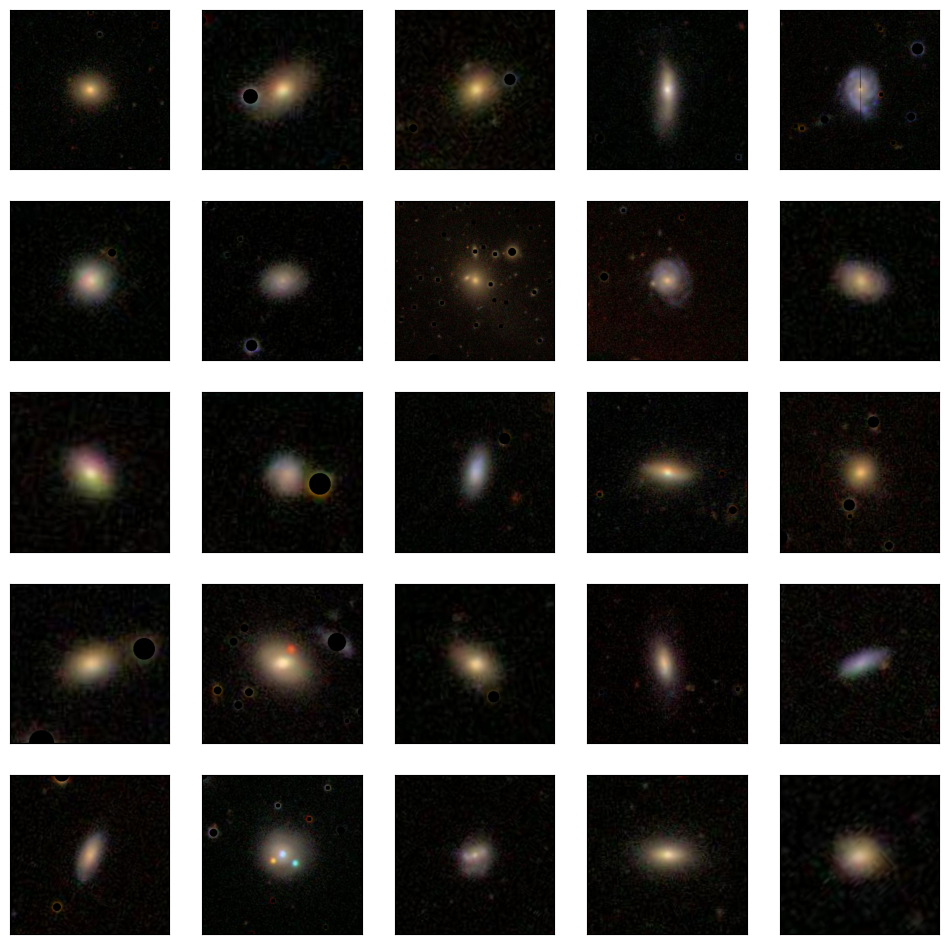

In [12]:
fig, axes = plt.subplots(ncols= 5, nrows = 5,figsize=(12,12))

ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans == 0])[1]),25)):
    img = skimage.io.imread(ruta+str(np.where([y_kmeans == 0])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

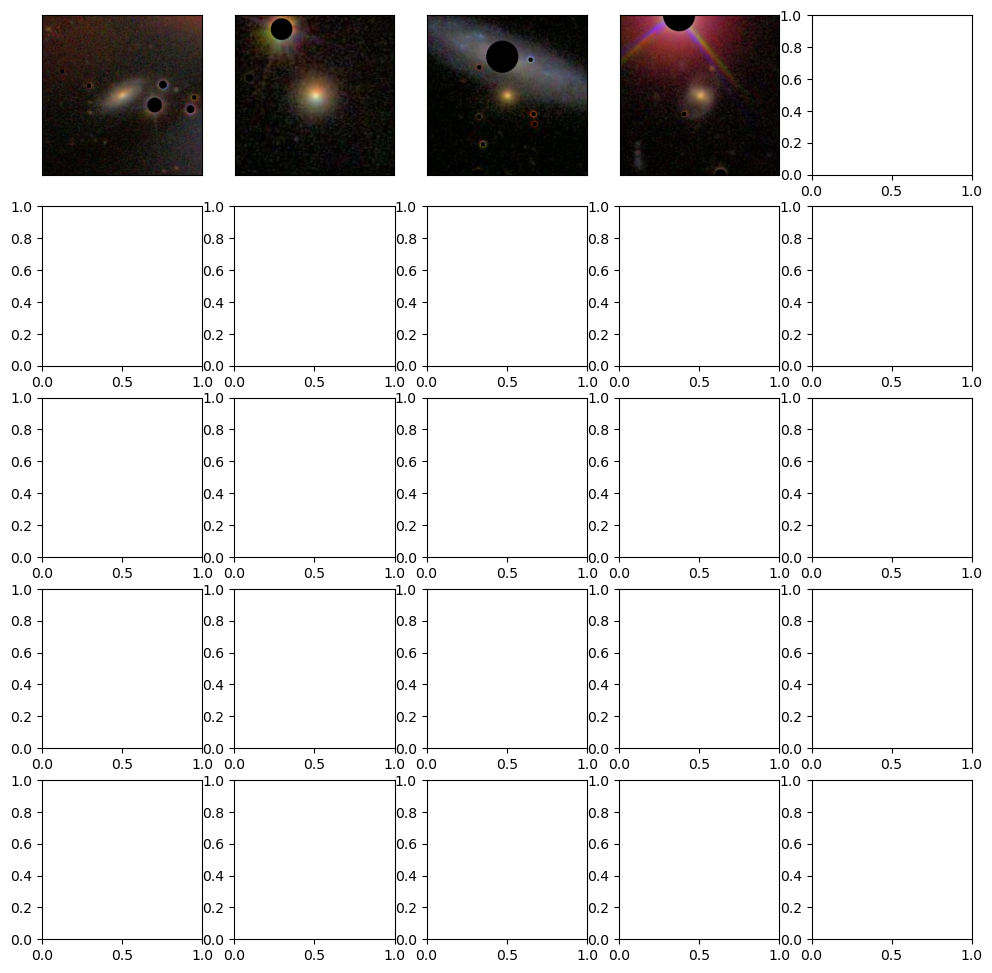

In [13]:
fig, axes = plt.subplots(ncols= 5, nrows = 5,figsize=(12,12))

ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans == 2])[1]),25)):
    img = skimage.io.imread(ruta+str(np.where([y_kmeans == 2])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

#### Verifique su resultado para cada cluster

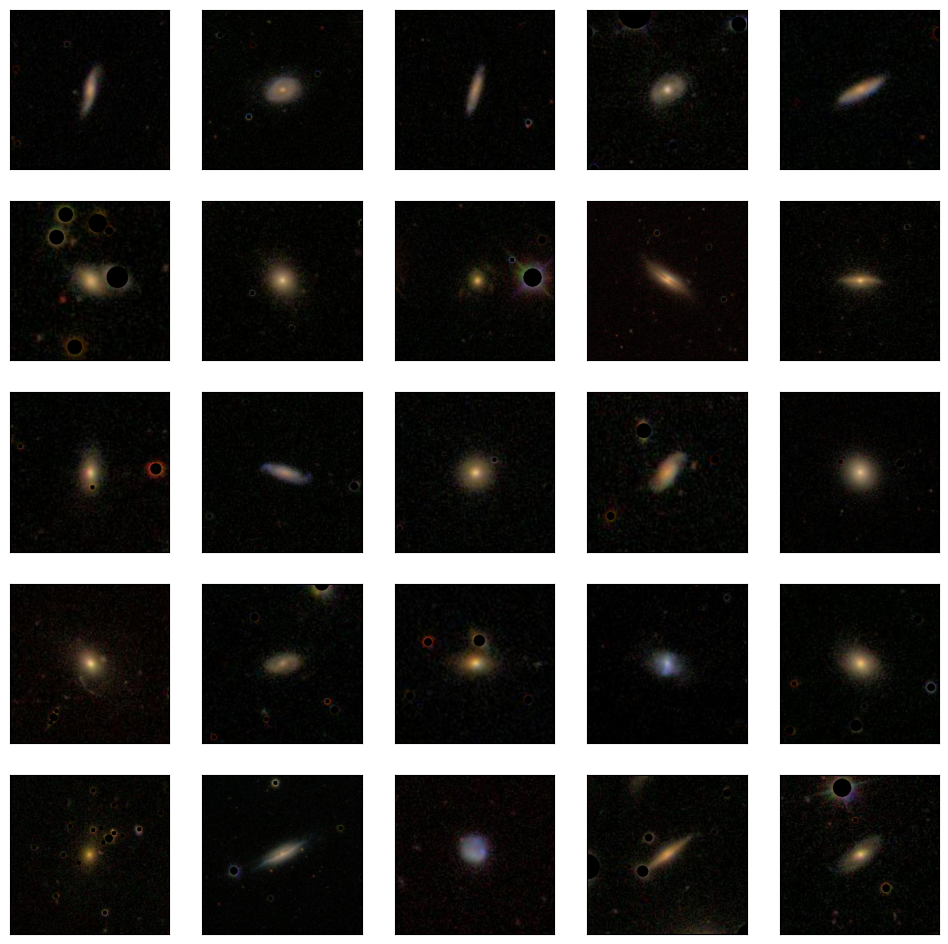

In [14]:
fig, axes = plt.subplots(ncols=5, nrows=5, figsize=(12,12))
ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans == 1])[1]),25)):
    img = skimage.io.imread(ruta+str(np.where([y_kmeans == 1])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

### Puede identificar algún criterio de separación de los grupos?



Sí, se separan por brillo y tamaño aparente, no por forma.

- Grupo 0: galaxias más grandes y brillantes.
- Grupo 1: galaxias pequeñas y débiles.
- Grupo 2: pocas imágenes con el fondo contaminado por estrellas brillantes o halos.

### Probemos aplicando PCA antes de clusterizar

Si los clusters parecen agrupar más por brillo o tamaño que por forma, puede ser porque K-means sobre píxeles crudos usa distancia euclidiana, muy sensible a esas variables.

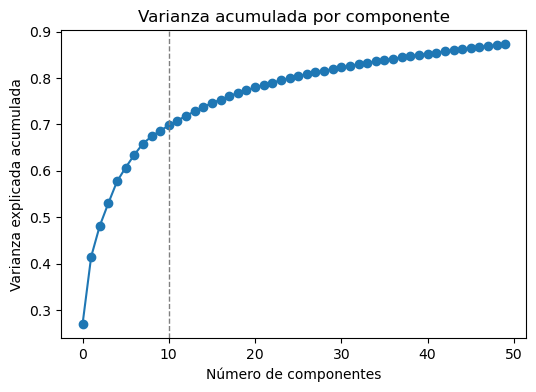

Varianza explicada con 10 componentes: 68.65%


In [15]:
from sklearn.decomposition import PCA

n_componentes = 10
pca = PCA(n_components=50, random_state=10)
images_pca_full = pca.fit_transform(images)

plt.figure(figsize=(6,4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), 'o-')
plt.axvline(n_componentes, color='gray', linestyle='--', linewidth=1)
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza acumulada por componente')
plt.show()

images_pca = images_pca_full[:, :n_componentes]
print(f"Varianza explicada con {n_componentes} componentes: {np.cumsum(pca.explained_variance_ratio_)[n_componentes-1]:.2%}")

In [16]:
kmeans_pca = KMeans(n_clusters=grupos, n_init=10, random_state=10)
y_kmeans_pca = kmeans_pca.fit_predict(images_pca)

comparacion = pd.crosstab(y_kmeans, y_kmeans_pca,
                          rownames=['Cluster (píxeles crudos)'],
                          colnames=['Cluster (PCA)'])
comparacion

Cluster (PCA),0,1,2
Cluster (píxeles crudos),,,
0,57,0,0
1,0,139,0
2,0,0,4


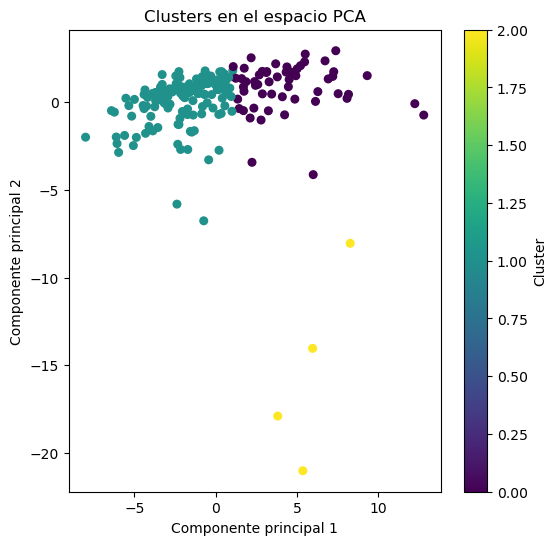

In [17]:
plt.figure(figsize=(6,6))
scatter = plt.scatter(images_pca[:,0], images_pca[:,1], c=y_kmeans_pca, cmap='viridis', s=30)
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Clusters en el espacio PCA')
plt.colorbar(scatter, label='Cluster')
plt.show()

#### Observemos algunas galaxias de los nuevos clusters (con PCA)

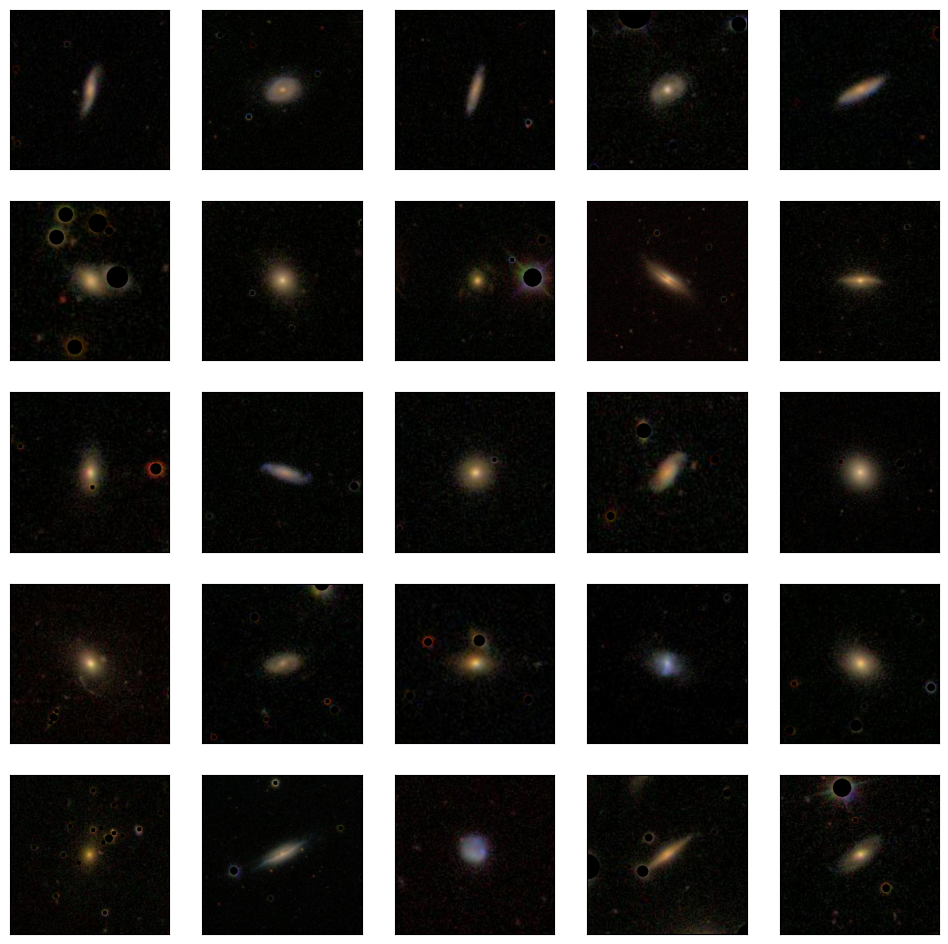

In [18]:
fig, axes = plt.subplots(ncols=5, nrows=5, figsize=(12,12))
ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans_pca == 1])[1]),25)):
    img = skimage.io.imread(ruta+str(np.where([y_kmeans_pca == 1])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

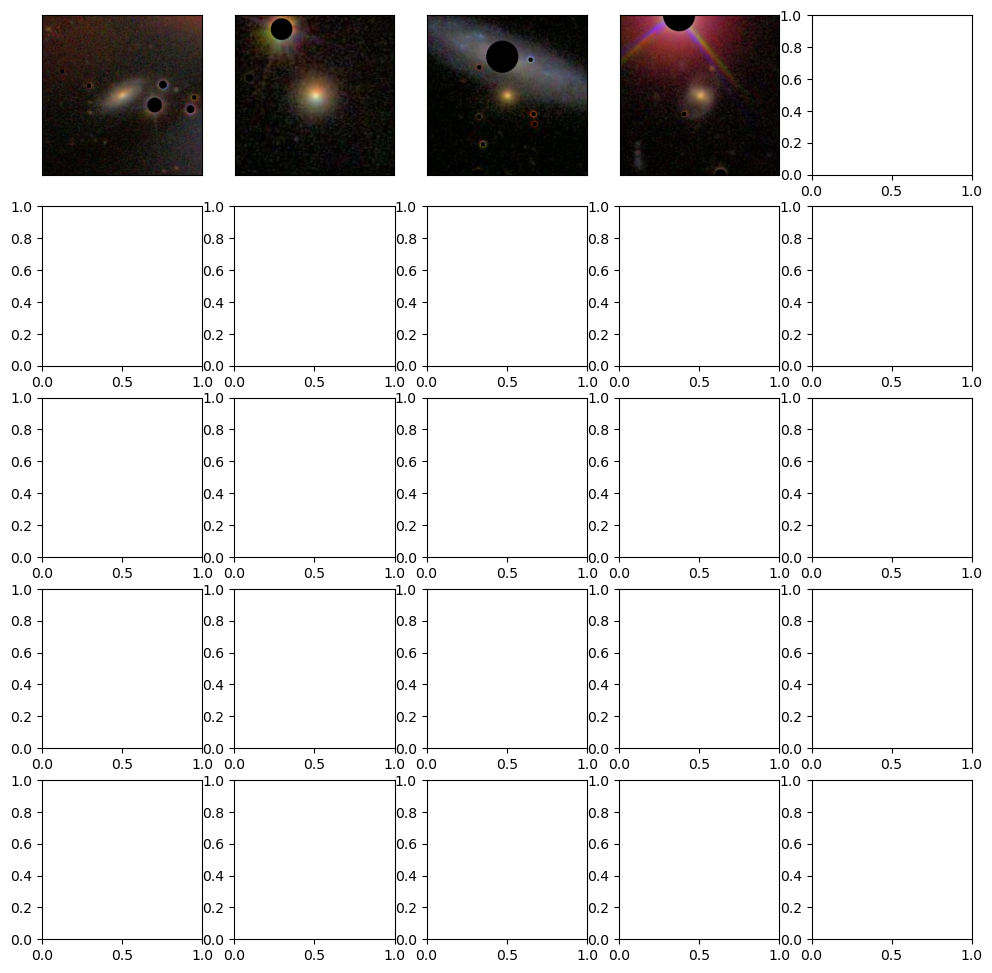

In [19]:
fig, axes = plt.subplots(ncols=5, nrows=5, figsize=(12,12))
ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans_pca == 2])[1]),25)):
    img = skimage.io.imread(ruta+str(np.where([y_kmeans_pca == 2])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

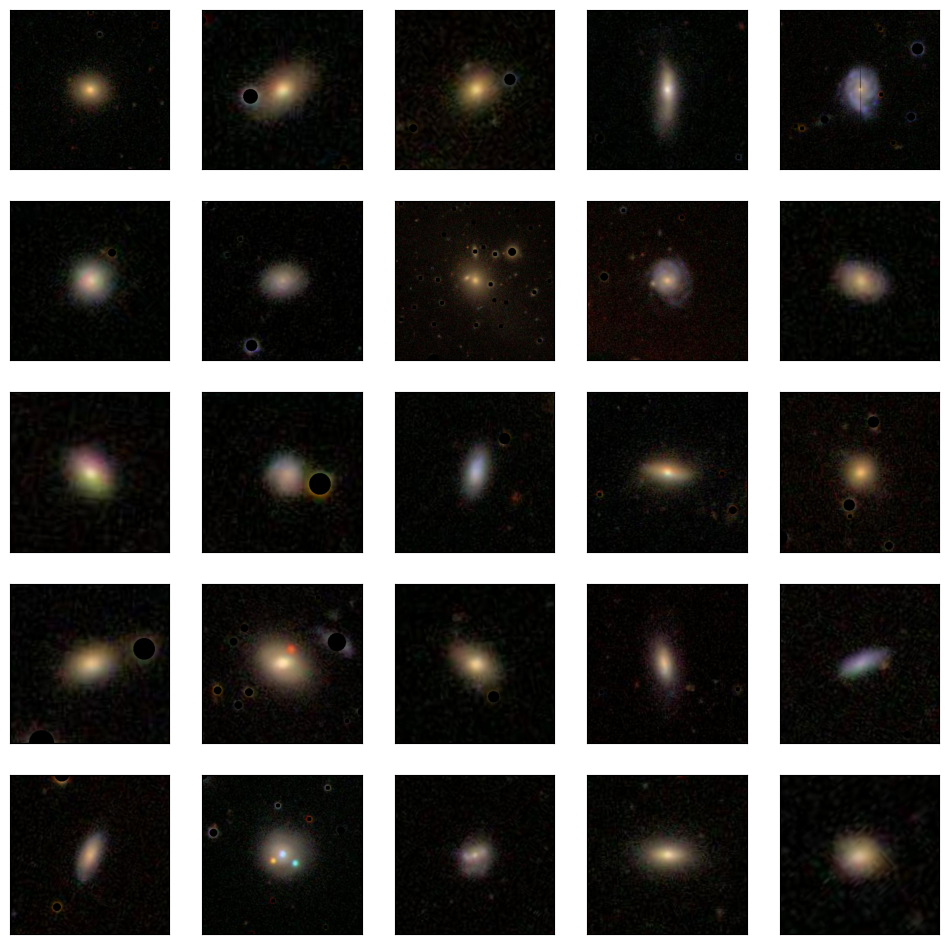

In [20]:
fig, axes = plt.subplots(ncols=5, nrows=5, figsize=(12,12))
ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans_pca == 0])[1]),25)):
    img = skimage.io.imread(ruta+str(np.where([y_kmeans_pca == 0])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

**¿Cambió el criterio de separación con PCA? Miren la tabla cruzada: ¿las mismas galaxias quedaron juntas en ambos métodos? ¿Qué les parece que capturan las primeras componentes principales?**

No cambió. La tabla cruzada es diagonal, así que las mismas galaxias quedaron juntas con ambos métodos.

La primera componente sigue el brillo central de la galaxia (su tamaño y luminosidad) y la segunda la luz en los bordes de la imagen (contaminación del fondo). Ninguna captura la morfología.